# 01 · Base: red de pagos y déficit de liquidez

Modelo lineal $\dot x = (-\alpha I + \beta W)x$. Índice de amplificación $R = \beta\rho(W)/\alpha$: si $R<1$ la red amortigua; si $R>1$ amplifica.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
TOPO_LABEL = {"erdos_renyi": "Erdős–Rényi", "barabasi_albert": "Barabási–Albert",
              "core_periphery": "Núcleo-periferia"}

In [2]:
from pulso.networks import NetworkConfig, generate

def_cfg = dict(n=120, mean_degree=6.0, amount_sigma=0.8, core_frac=0.1, p_core=0.8,
               periphery_share=0.1, seed=1)
nets = {t: generate(NetworkConfig(topology=t, **def_cfg)) for t in TOPO_LABEL}
from pulso.spectral import perron_root
{TOPO_LABEL[t]: round(perron_root(W), 2) for t, W in nets.items()}

{'Erdős–Rényi': 9.0, 'Barabási–Albert': 11.91, 'Núcleo-periferia': 13.85}

## Trayectorias con $R<1$ y $R>1$
Choque unitario en la entidad más importante.

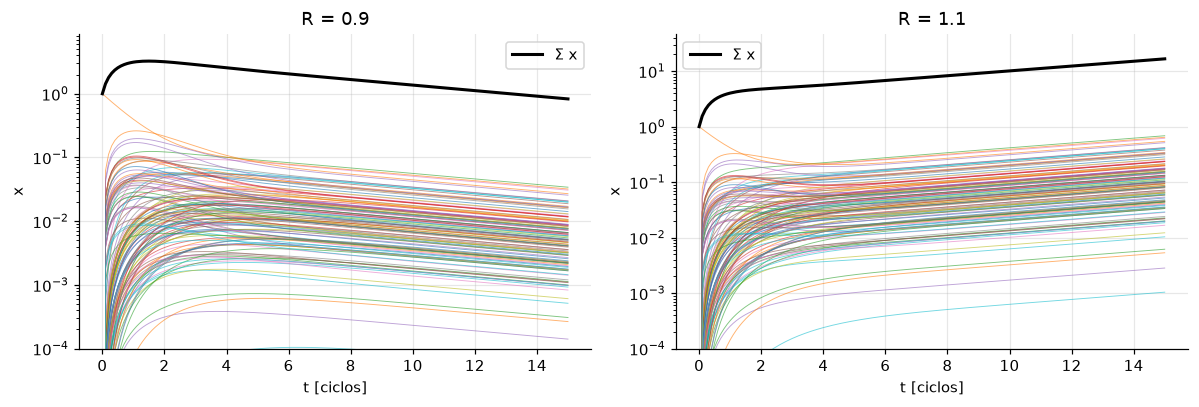

In [3]:
from pulso.integrate import simulate
from pulso.model import Params
from pulso.spectral import entity_ranking

W = nets["core_periphery"]
rho = perron_root(W)
top = int(entity_ranking(W)["entidad"].iloc[0])
x0 = np.zeros(W.shape[0]); x0[top] = 1.0
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, R in zip(axes, [0.9, 1.1]):
    traj = simulate(W, Params(alpha=1.0, beta=R / rho), t_end=15, dt=0.01, x0=x0, save_every=10)
    ax.plot(traj.t, traj.x, lw=0.6, alpha=0.6)
    ax.plot(traj.t, traj.x.sum(1), "k", lw=2, label="Σ x")
    ax.set(title=f"R = {R}", xlabel="t [ciclos]", ylabel="x", yscale="log", ylim=(1e-4, None))
    ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fase1_trayectorias.png")

## Diagrama de fase $\alpha$–$\beta$ por topología
Color: $\sigma = \max\mathrm{Re}\,\lambda(M)$. La frontera $\sigma=0$ es la recta $\beta = \alpha/\rho(W)$: la topología solo entra por $\rho(W)$.

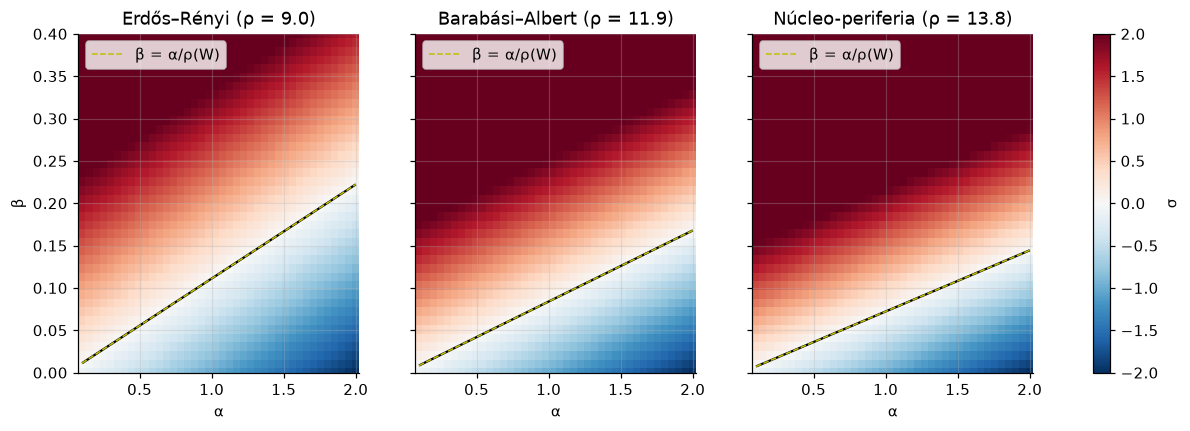

In [4]:
from pulso.spectral import stability

alphas = np.linspace(0.1, 2.0, 40)
betas = np.linspace(0.0, 0.4, 40)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (t, W) in zip(axes, nets.items()):
    rho = perron_root(W)
    S = np.array([[stability(W, Params(alpha=a, beta=b)) for a in alphas] for b in betas])
    im = ax.pcolormesh(alphas, betas, S, cmap="RdBu_r", vmin=-2, vmax=2, shading="auto")
    ax.contour(alphas, betas, S, levels=[0], colors="k", linewidths=1.5)
    ax.plot(alphas, alphas / rho, "y--", lw=1, label="β = α/ρ(W)")
    ax.set(title=f"{TOPO_LABEL[t]} (ρ = {rho:.1f})", xlabel="α", ylim=(0, betas[-1]))
    ax.legend(loc="upper left")
axes[0].set_ylabel("β")
fig.colorbar(im, ax=axes, label="σ")
fig.savefig(FIG / "fase1_diagrama_alpha_beta.png", bbox_inches="tight")

## Ranking de entidades
Vector propio izquierdo (importancia: cuánto propaga) contra pagos salientes.

,entidad,importancia,vulnerabilidad,paga,recibe
0,11,0.049567,0.038598,87.648766,51.529604
1,3,0.045849,0.014041,32.943055,20.982662
2,8,0.036793,0.012341,38.143549,12.405017
3,0,0.034603,0.017070,32.011280,20.645792
4,4,0.032168,0.025147,36.752501,28.266101
5,9,0.032151,0.024054,41.755068,23.189429
6,6,0.030363,0.037042,37.853198,55.987227
7,2,0.028840,0.041168,45.553755,55.274324
8,108,0.028355,0.009338,13.426278,7.789854
9,89,0.025379,0.007088,12.238992,4.858919


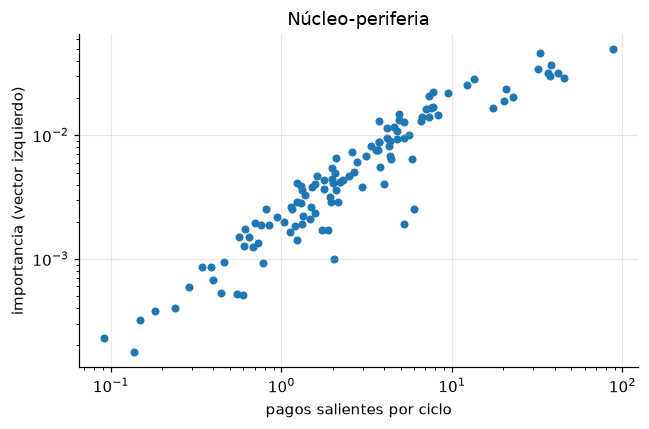

In [5]:
rk = entity_ranking(nets["core_periphery"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(rk["paga"], rk["importancia"], s=18)
ax.set(xlabel="pagos salientes por ciclo", ylabel="importancia (vector izquierdo)",
       xscale="log", yscale="log", title="Núcleo-periferia")
fig.tight_layout(); fig.savefig(FIG / "fase1_ranking.png")
rk.head(10)